# JC 单小时历史预测回放
选择一个已有的 America/New_York 历史小时，模型只读取该小时之前的 168 小时信息与已知日历特征。真实出发量仅用于事后对照。
这是历史回放，不是实时预测服务：数据集截至 2025-12-31，不能预测当前现实中的下一小时；未来天气预报接入也尚未实现。

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.jc_baseline_models import load_weathered_2024_2025
from src.jc_demo_prediction import predict_historical_hour
frame = load_weathered_2024_2025()
available_end = frame['local_time'].max()
target_local = None  # None selects latest historical hour; or set e.g. '2025-12-31 23:00'
result = predict_historical_hour(frame, target_local)
result

{'target_local_time': '2025-12-31 23:00:00',
 'target_utc': '2026-01-01T04:00:00+00:00',
 'predictor_time_utc': '2026-01-01T03:00:00+00:00',
 'train_end_exclusive_utc': '2025-01-01T05:00:00+00:00',
 'history_hours': 168,
 'device': 'cuda',
 'lstm_epochs': 26,
 'predictions': {'random_forest': 20.48182738095237,
  'lstm_168h': 22.828889557340915},
 'actual_for_historical_replay_only': 22.0,
 'note': 'Historical one-step replay; actual is returned only for display and is never used as an input.'}

## 回放对照
预测值在原始每小时出发次数尺度上。模型每次运行会用 2024 年开发期重新拟合；目标小时的真实值只用于本单元展示误差，不参与特征或拟合。

,model,predicted_departures,actual_departures_replay_only,absolute_error
0,random_forest,20.481827,22.0,1.518173
1,lstm_168h,22.828890,22.0,0.828890


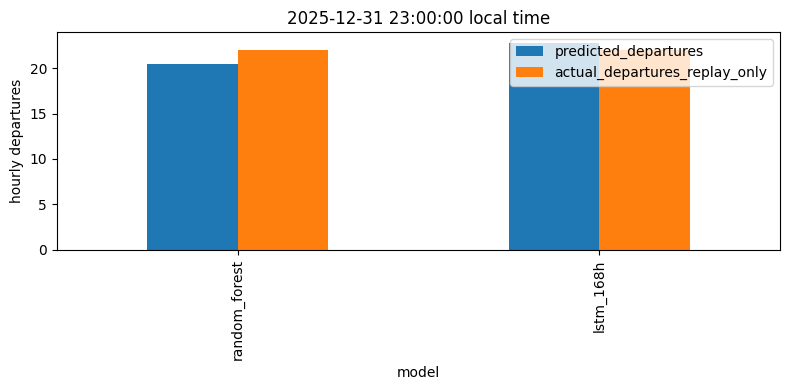

In [2]:
comparison = pd.DataFrame({
    'model': list(result['predictions']),
    'predicted_departures': list(result['predictions'].values()),
})
comparison['actual_departures_replay_only'] = result['actual_for_historical_replay_only']
comparison['absolute_error'] = (comparison['predicted_departures'] - comparison['actual_departures_replay_only']).abs()
display(comparison)
ax = comparison.set_index('model')[['predicted_departures','actual_departures_replay_only']].plot.bar(figsize=(8,4))
ax.set_ylabel('hourly departures'); ax.set_title(result['target_local_time'] + ' local time'); plt.tight_layout()
plt.show()

## 边界
项目数据截至 2025 年底，所以当前只能回放历史时点。要用于真实业务，还需持续更新行程/供给数据、定义服务可用性与缺数策略、接入当时可获得的未来天气预报，并部署预测接口。